# (KNN) Classification on CKD Dataset

In [59]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix


### Repository setup
This repository version uses the files under `data/` directly. The original Colab Drive mount has been removed for portability.


In [61]:
df = pd.read_csv("/content/drive/MyDrive/CKD/final_intersection_dataset (1).csv")

In [63]:
target_col = 'classification' if 'classification' in df.columns else 'target'

In [64]:
# Check the columns in the DataFrame to identify the correct target column name
print(df.columns)

# Once the correct column name is identified, replace 'target' in the next line
X = df.drop(columns=[target_col])
y = df[target_col]

Index(['sg', 'id', 'rbc', 'bgr', 'hemo', 'htn', 'al', 'classification'], dtype='object')


In [65]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [66]:
from sklearn.impute import SimpleImputer

# Impute missing values with the mean
imputer = SimpleImputer(strategy='mean')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [67]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

KNeighborsClassifier()

In [68]:
y_pred = knn.predict(X_test)

In [69]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

In [70]:
print("KNN Classification Results:")
print("---------------------------")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")
print("\nConfusion Matrix:\n", cm)

KNN Classification Results:
---------------------------
Accuracy : 0.9833
Precision: 0.9868
Recall   : 0.9868
F1-Score : 0.9868

Confusion Matrix:
 [[43  1]
 [ 1 75]]


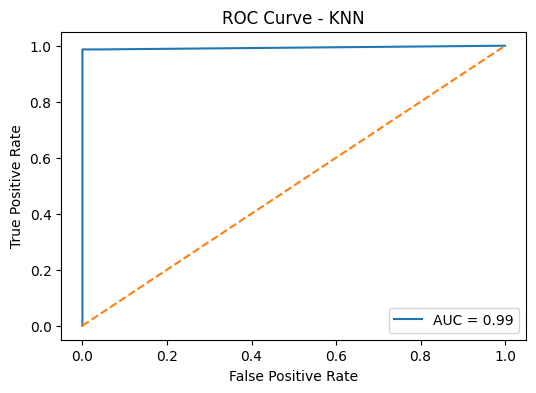

In [72]:
from sklearn.metrics import roc_curve, auc

y_prob = knn.predict_proba(X_test)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0,1], [0,1], '--')
plt.title("ROC Curve - KNN")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()


#CNN Classification on CKD Dataset (Tabular using 1D CNN)

In [12]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
import seaborn as sns
import matplotlib.pyplot as plt

In [13]:
df = pd.read_csv("/content/drive/MyDrive/CKD/final_intersection_dataset (1).csv")

In [14]:
df = df.replace('?', np.nan)
df = df.dropna(axis=0)  # drop missing rows
df = df.drop_duplicates()

In [15]:
# Encode categorical columns
for col in df.select_dtypes(include=['object']).columns:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))

In [16]:
# Split features and target
target_col = 'classification' if 'classification' in df.columns else df.columns[-1]
X = df.drop(columns=[target_col]).values
y = df[target_col].values

In [17]:
# Ensure binary encoding (0/1)
if y.max() > 1:
    y = LabelEncoder().fit_transform(y)

In [18]:
# Split and scale
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [19]:
# Reshape for 1D CNN
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

In [20]:
# Build 1D CNN model
model = Sequential([
    Conv1D(128, 3, activation='relu', input_shape=(X_train.shape[1], 1)),
    BatchNormalization(),
    MaxPooling1D(2),
    Dropout(0.3),

    Conv1D(64, 2, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer=Adam(learning_rate=0.0005),
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 5, 128)         │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 5, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 2, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 1, 64)          │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,953 (85.75 KB)

 Trainable params: 21,569 (84.25 KB)

 Non-trainable params: 384 (1.50 KB)

In [21]:
# Train
es = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1)

history = model.fit(
    X_train, y_train,
    epochs=80,
    batch_size=16,
    validation_split=0.2,
    callbacks=[es],
    verbose=1
)

Epoch 1/80
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.7471 - loss: 0.5174 - val_accuracy: 0.9778 - val_loss: 0.6327
Epoch 2/80
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9654 - loss: 0.2326 - val_accuracy: 0.9111 - val_loss: 0.6122
Epoch 3/80
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9955 - loss: 0.1441 - val_accuracy: 0.9111 - val_loss: 0.5887
Epoch 4/80
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9569 - loss: 0.1425 - val_accuracy: 0.9111 - val_loss: 0.5778
Epoch 5/80
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9809 - loss: 0.1125 - val_accuracy: 0.9111 - val_loss: 0.5640
Epoch 6/80
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9715 - loss: 0.1026 - val_accuracy: 0.9111 - val_loss: 0.5451
Epoch 7/80
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9991 - loss: 0.0690 - val_accuracy: 0.9333 - val_loss: 0.5164
Epoch 8/80
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9908 - loss: 0.0683 - val_accuracy: 0.9556 - v

In [22]:
# Evaluate
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\nCNN Model Performance:")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1 Score  : {f1:.4f}")

print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step

CNN Model Performance:
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1 Score  : 1.0000

Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        27
           1     1.0000    1.0000    1.0000        29

    accuracy                         1.0000        56
   macro avg     1.0000    1.0000    1.0000        56
weighted avg     1.0000    1.0000    1.0000        56


Confusion Matrix:
 [[27  0]
 [ 0 29]]


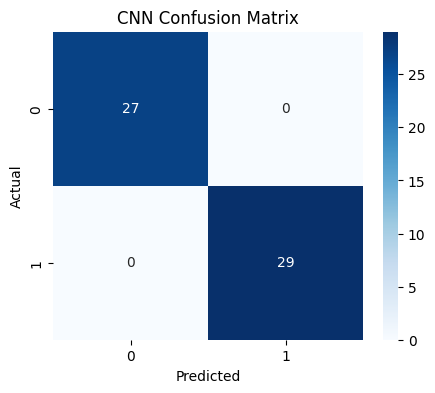

In [23]:
# Confusion Matrix Plot
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('CNN Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# CNN + KNN Classification on CKD Dataset

In [24]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, Flatten, Dropout, MaxPooling1D
from tensorflow.keras.optimizers import Adam

In [25]:
df = pd.read_csv("/content/drive/MyDrive/CKD/final_intersection_dataset (1).csv")

In [26]:
target_col = 'classification'

In [27]:
X = df.drop(columns=[target_col])
y = df[target_col]

In [71]:
from sklearn.impute import SimpleImputer

# Replace '?' with NaN and convert relevant columns to numeric
X = X.replace('?', np.nan)
for col in X.columns:
    if X[col].dtype == 'object':
        X[col] = pd.to_numeric(X[col], errors='coerce')

# Impute missing values with the mean
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

In [29]:
# Split for both models
X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.3, random_state=42)

In [30]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

knn_acc = accuracy_score(y_test, y_pred_knn)
knn_prec = precision_score(y_test, y_pred_knn)
knn_rec = recall_score(y_test, y_pred_knn)
knn_f1 = f1_score(y_test, y_pred_knn)

In [31]:
X_train_cnn = np.expand_dims(X_train, axis=2)
X_test_cnn = np.expand_dims(X_test, axis=2)

cnn = Sequential([
    Conv1D(64, kernel_size=2, activation='relu', input_shape=(X_train_cnn.shape[1], 1)),
    MaxPooling1D(pool_size=2),
    Dropout(0.3),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

cnn.compile(optimizer=Adam(learning_rate=0.001),
            loss='binary_crossentropy',
            metrics=['accuracy'])

cnn.fit(X_train_cnn, y_train, epochs=30, batch_size=16, verbose=0, validation_split=0.2)

y_pred_cnn = (cnn.predict(X_test_cnn) > 0.5).astype(int)

cnn_acc = accuracy_score(y_test, y_pred_cnn)
cnn_prec = precision_score(y_test, y_pred_cnn)
cnn_rec = recall_score(y_test, y_pred_cnn)
cnn_f1 = f1_score(y_test, y_pred_cnn)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


In [32]:
results = pd.DataFrame({
    "Model": ["KNN", "CNN"],
    "Accuracy": [knn_acc, cnn_acc],
    "Precision": [knn_prec, cnn_prec],
    "Recall": [knn_rec, cnn_rec],
    "F1-Score": [knn_f1, cnn_f1]
})

results.to_csv("cnn_knn_comparison_results.csv", index=False)
print("✅ Saved: cnn_knn_comparison_results.csv")

print("\nModel Performance Comparison:")
print(results)

✅ Saved: cnn_knn_comparison_results.csv

Model Performance Comparison:
  Model  Accuracy  Precision    Recall  F1-Score
0   KNN  0.991667   1.000000  0.986842  0.993377
1   CNN  0.933333   0.959459  0.934211  0.946667


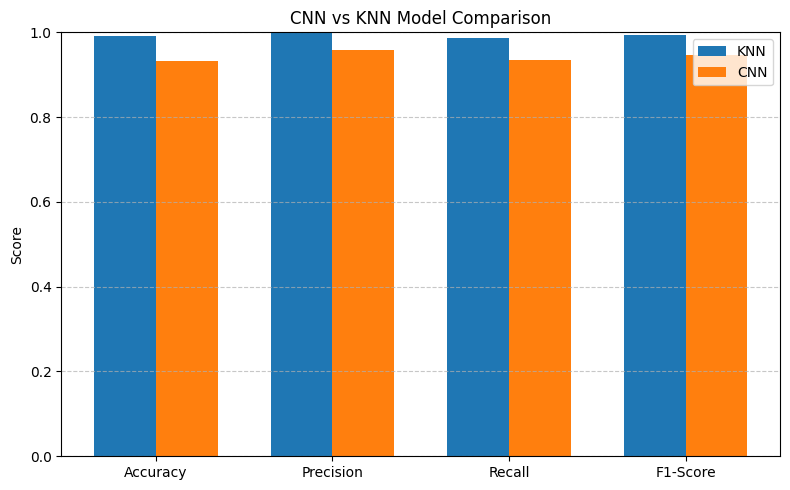

In [33]:
# Visualization
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8,5))
plt.bar(x - width/2, results.iloc[0, 1:], width, label='KNN')
plt.bar(x + width/2, results.iloc[1, 1:], width, label='CNN')

plt.xticks(x, metrics)
plt.ylabel('Score')
plt.title('CNN vs KNN Model Comparison')
plt.legend()
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Hybrid 1D CNN + KNN Model for CKD Classification
# CNN extracts features, KNN performs classification

In [34]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, Input

In [35]:
df = pd.read_csv("/content/drive/MyDrive/CKD/final_intersection_dataset (1).csv")

In [36]:
# Identify target column
target_col = 'classification' if 'classification' in df.columns else 'target'

In [37]:
# Separate features and target
X = df.drop(columns=[target_col])
y = df[target_col]

In [38]:
from sklearn.impute import SimpleImputer

# Impute missing values with the mean
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

# 2. Normalize and Split Dataset
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

In [39]:
# Reshape for CNN input (samples, features, 1)
X_train_cnn = np.expand_dims(X_train, axis=2)
X_test_cnn = np.expand_dims(X_test, axis=2)

In [40]:
# 3. Define 1D CNN Feature Extractor
cnn_model = Sequential([
    Conv1D(64, kernel_size=2, activation='relu', input_shape=(X_train_cnn.shape[1], 1)),
    MaxPooling1D(pool_size=2),
    Dropout(0.3),
    Conv1D(128, kernel_size=2, activation='relu'),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.3)
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [41]:
# Build CNN feature extractor (no final classification layer)
cnn_model.compile(optimizer='adam')

In [42]:
# Train CNN to learn meaningful representations
# cnn_model.fit(X_train_cnn, y_train, epochs=30, batch_size=16, verbose=0, validation_split=0.2)

In [43]:
# Extract CNN Features
X_train_features = cnn_model.predict(X_train_cnn)
X_test_features = cnn_model.predict(X_test_cnn)

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


In [44]:
# 5. Train KNN Classifier on CNN Features

# Check for NaNs in extracted features
print("NaNs in X_train_features:", np.isnan(X_train_features).sum())
print("NaNs in X_test_features:", np.isnan(X_test_features).sum())

from sklearn.impute import SimpleImputer

# Impute missing values in extracted features
imputer_features = SimpleImputer(strategy='mean')
X_train_features_imputed = imputer_features.fit_transform(X_train_features)
X_test_features_imputed = imputer_features.transform(X_test_features)


knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_features_imputed, y_train)
y_pred = knn.predict(X_test_features_imputed)

NaNs in X_train_features: 0
NaNs in X_test_features: 0


In [45]:
# 6. Evaluate Hybrid Model
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

In [46]:
# Display and Save Results
results = pd.DataFrame({
    "Model": ["Hybrid 1D CNN + KNN"],
    "Accuracy": [acc],
    "Precision": [prec],
    "Recall": [rec],
    "F1-Score": [f1]
})
print("\n✅ Hybrid Model Performance:")
print(results)

results.to_csv("hybrid_cnn_knn_results.csv", index=False)
print("\n📁 Results saved as: hybrid_cnn_knn_results.csv")


✅ Hybrid Model Performance:
                 Model  Accuracy  Precision    Recall  F1-Score
0  Hybrid 1D CNN + KNN      0.95   0.972973  0.947368      0.96

📁 Results saved as: hybrid_cnn_knn_results.csv


# Hybrid 1D CNN + KNN for CKD Dataset

In [47]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

In [48]:
df = pd.read_csv("/content/drive/MyDrive/CKD/final_intersection_dataset (1).csv")

In [49]:
#Encode target and split
y = LabelEncoder().fit_transform(df.iloc[:, -1])
X = df.iloc[:, :-1].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [50]:
#Scale data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [51]:
#Reshape for CNN input
X_train_cnn = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_cnn = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

In [52]:
#Build CNN for feature extraction
cnn = Sequential([
    Conv1D(64, 3, activation='relu', input_shape=(X_train.shape[1], 1)),
    BatchNormalization(),
    MaxPooling1D(2),
    Dropout(0.3),

    Conv1D(128, 2, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Flatten(),
    Dropout(0.3)
])

cnn.compile(optimizer=Adam(learning_rate=0.001)) # Removed loss and metrics

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [53]:
#Train CNN
# history = cnn.fit(
#     X_train_cnn, y_train,
#     epochs=40, batch_size=16,
#     validation_split=0.2, verbose=0
# )

In [54]:
#Extract CNN features
train_features = cnn.predict(X_train_cnn)
test_features = cnn.predict(X_test_cnn)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step  
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


In [55]:
#Train KNN classifier on CNN features
from sklearn.impute import SimpleImputer
import numpy as np

# Replace infinite values with NaN
train_features = np.where(np.isinf(train_features), np.nan, train_features)
test_features = np.where(np.isinf(test_features), np.nan, test_features)

# Impute missing values (including those that were infinity)
imputer_features = SimpleImputer(strategy='mean')
train_features_imputed = imputer_features.fit_transform(train_features)
test_features_imputed = imputer_features.transform(test_features)

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(train_features_imputed, y_train)
y_pred = knn.predict(test_features_imputed)

/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:52: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: [  0   1   2   5   6  15  16  18  22  23  27  29  31  32  33  34  39  41
  43  44  50  52  54  55  59  60  61  63  65  66  67  68  71  72  76  77
  80  81  84  85  87  89  90  91  92  93  95  97 101 102 105 106 108 109
 112 113 114 115 117 118 119 122 125 127]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: [  0   1   2   5   6  15  16  18  22  23  27  29  31  32  33  34  39  41
  43  44  50  52  54  55  59  60  61  63  65  66  67  68  71  72  76  77
  80  81  84  85  87  89  90  91  92  93  95  97 101 102 105

In [56]:
#Evaluate model
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\n✅ Hybrid 1D CNN + KNN Model Performance:")
print(f"Accuracy : {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall   : {rec:.3f}")
print(f"F1 Score : {f1:.3f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


✅ Hybrid 1D CNN + KNN Model Performance:
Accuracy : 0.988
Precision: 0.980
Recall   : 1.000
F1 Score : 0.990

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98        30
           1       0.98      1.00      0.99        50

    accuracy                           0.99        80
   macro avg       0.99      0.98      0.99        80
weighted avg       0.99      0.99      0.99        80

Confusion Matrix:
[[29  1]
 [ 0 50]]


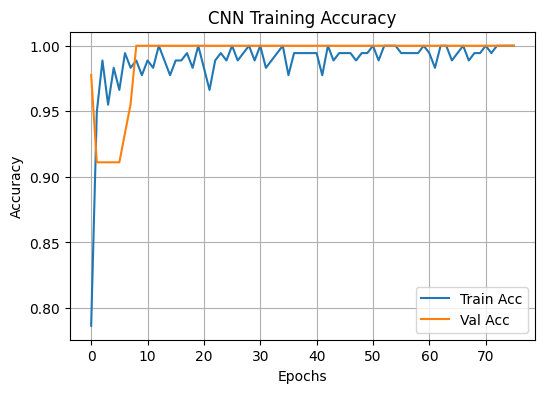

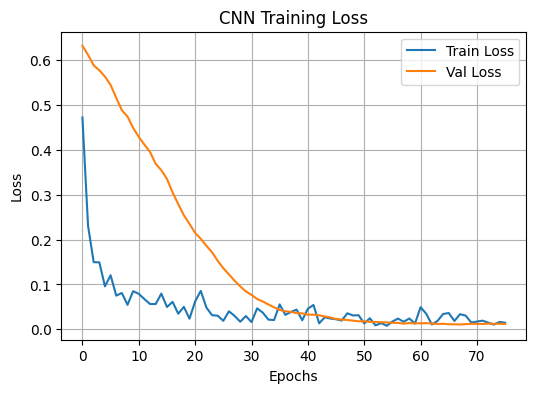

In [57]:
#Plot Accuracy & Loss curves
plt.figure(figsize=(6,4))
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('CNN Training Accuracy')
plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(6,4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('CNN Training Loss')
plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid(True); plt.show()

# CNN vs KNN vs Hybrid (CKD Dataset)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/CKD/final_intersection_dataset (1).csv")

In [ ]:
# Encode target
y = LabelEncoder().fit_transform(df.iloc[:, -1])
X = df.iloc[:, :-1].values

In [ ]:
# Split and scale
from sklearn.impute import SimpleImputer

# Impute missing values with the mean
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

scaler = StandardScaler()
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.2, random_state=42, stratify=y
)
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# CNN input shape
X_train_cnn = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_cnn = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

In [ ]:
# 1️⃣ KNN baseline
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
acc_knn = accuracy_score(y_test, y_pred_knn)
prec_knn = precision_score(y_test, y_pred_knn)
rec_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)

In [ ]:
# 2️⃣ CNN only
cnn = Sequential([
    Conv1D(64, 3, activation='relu', input_shape=(X_train.shape[1], 1)),
    BatchNormalization(),
    MaxPooling1D(2),
    Dropout(0.3),
    Conv1D(128, 2, activation='relu'),
    BatchNormalization(),
    Flatten(),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])
cnn.compile(optimizer=Adam(0.001), loss='binary_crossentropy', metrics=['accuracy'])
cnn.fit(X_train_cnn, y_train, epochs=40, batch_size=16, validation_split=0.2, verbose=0)
cnn_eval = cnn.evaluate(X_test_cnn, y_test, verbose=0)
acc_cnn = cnn_eval[1]
y_pred_cnn = (cnn.predict(X_test_cnn) > 0.5).astype(int)
prec_cnn = precision_score(y_test, y_pred_cnn)
rec_cnn = recall_score(y_test, y_pred_cnn)
f1_cnn = f1_score(y_test, y_pred_cnn)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# 3️⃣ Hybrid CNN + KNN
cnn_feature_extractor = Sequential(cnn.layers[:-1])  # remove final Dense layer
train_features = cnn_feature_extractor.predict(X_train_cnn)
test_features = cnn_feature_extractor.predict(X_test_cnn)

from sklearn.impute import SimpleImputer
import numpy as np

# Replace infinite values with NaN (though unlikely after scaling and CNN)
train_features = np.where(np.isinf(train_features), np.nan, train_features)
test_features = np.where(np.isinf(test_features), np.nan, test_features)

# Identify columns with all NaNs in training set
all_nan_cols = np.where(np.all(np.isnan(train_features), axis=0))[0]

# Replace columns with all NaNs with zeros in both train and test sets
train_features[:, all_nan_cols] = 0
test_features[:, all_nan_cols] = 0


# Impute remaining missing values
imputer_features = SimpleImputer(strategy='mean')
train_features_imputed = imputer_features.fit_transform(train_features)
test_features_imputed = imputer_features.transform(test_features)

knn_hybrid = KNeighborsClassifier(n_neighbors=3)
knn_hybrid.fit(train_features_imputed, y_train)
y_pred_hybrid = knn_hybrid.predict(test_features_imputed)

acc_hybrid = accuracy_score(y_test, y_pred_hybrid)
prec_hybrid = precision_score(y_test, y_pred_hybrid)
rec_hybrid = recall_score(y_test, y_pred_hybrid)
f1_hybrid = f1_score(y_test, y_pred_hybrid)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


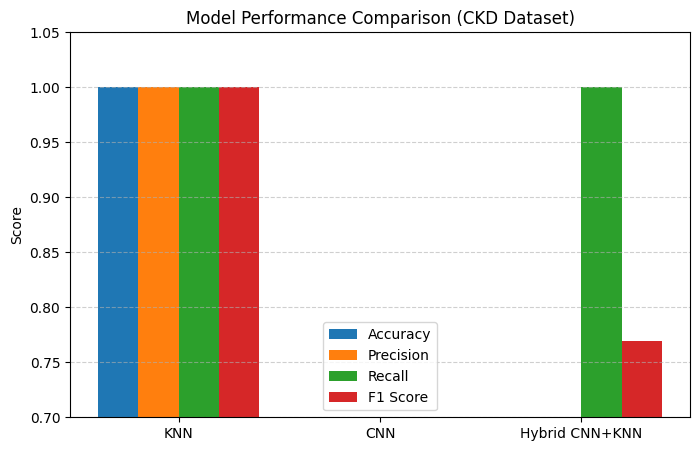

In [ ]:
#Comparison Bar Chart
models = ['KNN', 'CNN', 'Hybrid CNN+KNN']
accuracies = [acc_knn, acc_cnn, acc_hybrid]
precisions = [prec_knn, prec_cnn, prec_hybrid]
recalls = [rec_knn, rec_cnn, rec_hybrid]
f1s = [f1_knn, f1_cnn, f1_hybrid]

plt.figure(figsize=(8,5))
x = np.arange(len(models))
width = 0.2

plt.bar(x - 0.3, accuracies, width, label='Accuracy')
plt.bar(x - 0.1, precisions, width, label='Precision')
plt.bar(x + 0.1, recalls, width, label='Recall')
plt.bar(x + 0.3, f1s, width, label='F1 Score')

plt.xticks(x, models)
plt.ylim(0.7, 1.05)
plt.title("Model Performance Comparison (CKD Dataset)")
plt.ylabel("Score")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

In [ ]:
# Print final scores
print("\n✅ Final Results:")
for name, acc, f1 in zip(models, accuracies, f1s):
    print(f"{name:<15}  Accuracy: {acc:.3f}  F1 Score: {f1:.3f}")


✅ Final Results:
KNN              Accuracy: 1.000  F1 Score: 1.000
CNN              Accuracy: 0.375  F1 Score: 0.000
Hybrid CNN+KNN   Accuracy: 0.625  F1 Score: 0.769
